# Why isn't more of the sales money turning into profit?

This store has been selling more every year, and yet profit never quite keeps up. That's the question I started with. I went through four years of orders (9,994 order lines, January 2014 to December 2017) to find out where the money goes. It's all done in Python with pandas and matplotlib, and you can re-run everything from the CSV that sits next to this notebook.

If you only want the answer, jump to the last section. If you want to see how I got there, keep reading.

A heads-up on where this is going: the store keeps about 12.5 cents of every sales dollar, and the biggest reason it isn't more is discounting. Orders discounted past 20% lost around $135K on their own. Furniture and a handful of states make it worse. The details are below.

## First, is the data usable?

I always start here. I want to know there are no gaps, no duplicate rows, and that the dates are real dates and not just text.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format

DATA_PATH = "superstore.csv"   # keep the CSV in the same folder as this notebook
df = pd.read_csv(DATA_PATH, encoding="latin-1")
df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.62,2,0.00,6.87


In [2]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="%m/%d/%Y")
df["Year"]  = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

print("Rows, columns  :", df.shape)
print("Missing values :", int(df.isna().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Date range     :", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Rows, columns  : (9994, 23)
Missing values : 0
Duplicate rows : 0
Date range     : 2014-01-03 to 2017-12-30


It's clean. Nothing is missing and nothing is duplicated, so there's nothing to patch up. The data also covers four full years, which is handy later, because we can compare the same month across years instead of guessing.

## How much money are we talking about?

In [3]:
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()
losing_lines = df["Profit"] < 0

print(f"Total sales          : ${total_sales:,.0f}")
print(f"Total profit         : ${total_profit:,.0f}")
print(f"Overall margin       : {total_profit / total_sales:.1%}")
print(f"Lines that lost money: {losing_lines.mean():.1%} of all order lines")
print(f"Money lost on them   : -${abs(df.loc[losing_lines, 'Profit'].sum()):,.0f}")

Total sales          : $2,297,201
Total profit         : $286,397
Overall margin       : 12.5%
Lines that lost money: 18.7% of all order lines
Money lost on them   : -$156,131


In [4]:
by_year = df.groupby("Year")[["Sales", "Profit"]].sum()
by_year["Margin %"] = by_year["Profit"] / by_year["Sales"] * 100
by_year["Sales growth %"] = by_year["Sales"].pct_change() * 100
by_year

,Sales,Profit,Margin %,Sales growth %
Year,,,,
2014,"484,247.50","49,543.97",10.23,NaN
2015,"470,532.51","61,618.60",13.10,-2.83
2016,"609,205.60","81,795.17",13.43,29.47
2017,"733,215.26","93,439.27",12.74,20.36


Sales dipped a little in 2015, then jumped about 29% in 2016 and 20% in 2017. Profit grew too. But look at the margin column: it peaked at 13.4% in 2016 and fell back to 12.7% last year. So the store is selling more, but holding on to a slightly smaller slice of it.

## What does a normal order look like?

In [5]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


In [6]:
print("Average order-line sale :", round(df["Sales"].mean(), 2))
print("Median order-line sale  :", round(df["Sales"].median(), 2))

Average order-line sale : 229.86
Median order-line sale  : 54.49


The average sale is about $230, but the median is only $54. That gap tells you a few very large orders are pulling the average up (the biggest single line is over $22,000). So saying "the average order is $230" would be misleading, since most orders are far smaller than that.

The same lopsidedness shows up with customers. The top 20% of them, around 160 out of 793, account for roughly 48% of all sales.

## Do any of these numbers move together?

A quick correlation check on the four numeric columns. It runs from -1 to +1, and anything near zero means there's no straight-line link.

In [7]:
df[["Sales", "Quantity", "Discount", "Profit"]].corr().round(2)

,Sales,Quantity,Discount,Profit
Sales,1.00,0.20,-0.03,0.48
Quantity,0.20,1.00,0.01,0.07
Discount,-0.03,0.01,1.00,-0.22
Profit,0.48,0.07,-0.22,1.00


Profit and sales sit at 0.48. Bigger orders tend to earn more, which makes sense, though the link isn't tight. The one that caught my eye is profit and discount at -0.22. It's the only pair that points the wrong way: the more we discount, the less we make. It doesn't look dramatic as a number, but chart 3 shows there's a cliff hiding behind it.

Quantity hardly matters (0.07). Putting more units in an order doesn't make it more profitable.

One caution. A correlation can't tell us discounts *cause* the losses. Maybe discounts were handed out on products that were already hard to make money on. I'd still act on it, but I wouldn't claim more than the data shows.

## Three charts that tell the story

### 1. When do people buy?

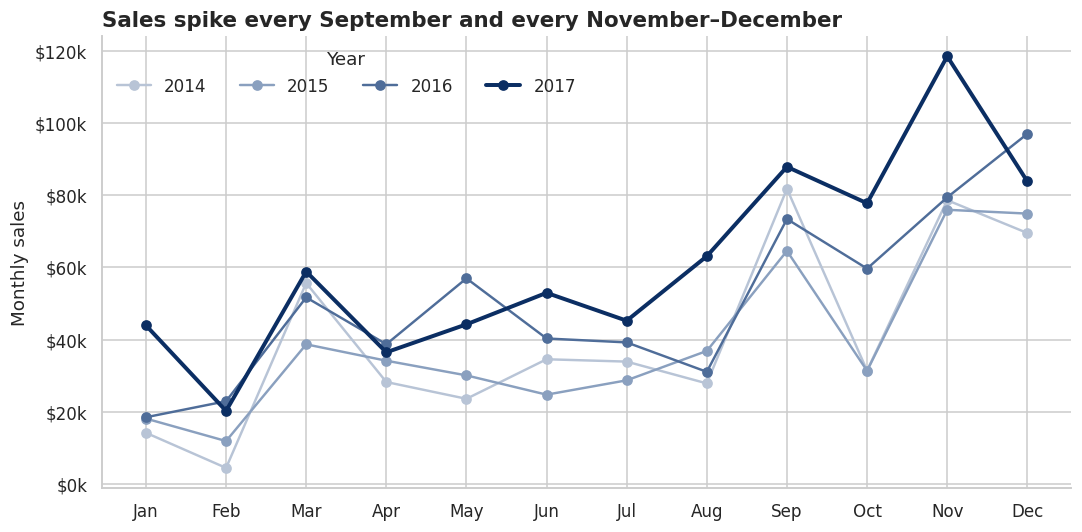

In [8]:
monthly = df.groupby(["Year", "Month"])["Sales"].sum().unstack(0)
palette = {2014: "#b8c4d6", 2015: "#8aa0bf", 2016: "#4f6d99", 2017: "#0b2e63"}
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(10, 5))
for year in monthly.columns:
    ax.plot(monthly.index, monthly[year], marker="o", color=palette[year],
            lw=2.6 if year == 2017 else 1.6, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}k")
ax.set_ylabel("Monthly sales")
ax.set_title("Sales spike every September and every November–December",
             loc="left", fontsize=14, fontweight="bold")
ax.legend(title="Year", frameon=False, ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

The shape repeats in all four years. January and February are quiet, March gets a lift, the middle of the year is flat, then September jumps and November and December jump higher still. November and December together make up almost 30% of the year's sales, and February is by far the weakest month.

That's useful for planning. Stock and staffing should follow those peaks, and the quiet months are the obvious place to run a deliberate offer.

### 2. Which products actually make money?

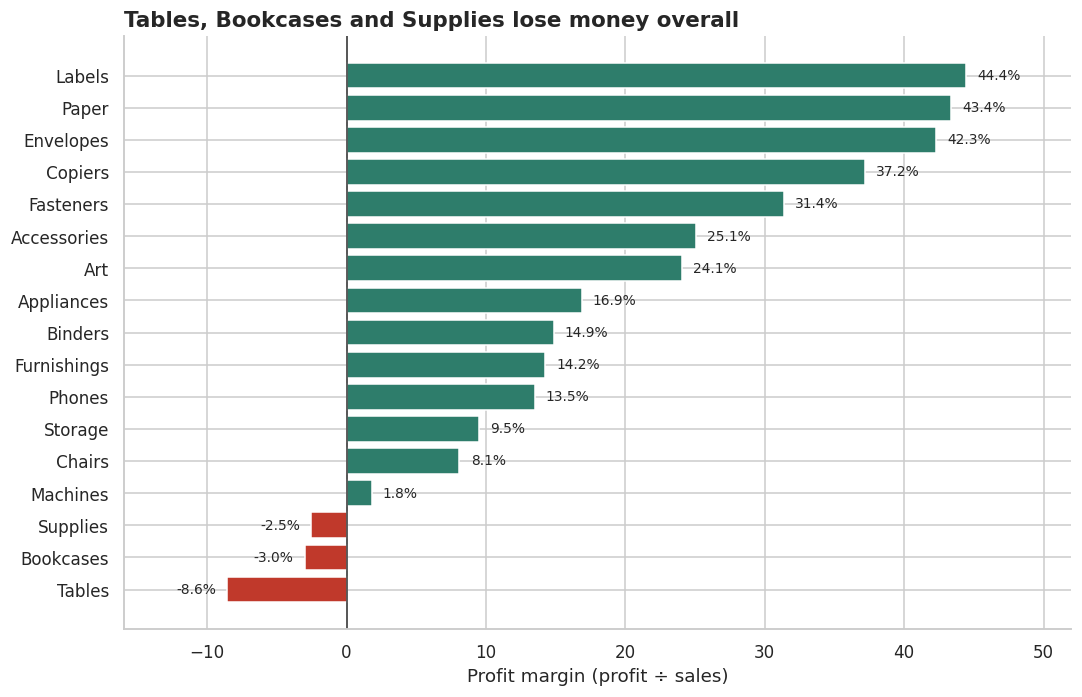

In [9]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
sub["Margin"] = sub["Profit"] / sub["Sales"] * 100
sub = sub.sort_values("Margin")
colors = ["#c0392b" if m < 0 else "#2e7d6b" for m in sub["Margin"]]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(sub.index, sub["Margin"], color=colors)
for y, m in enumerate(sub["Margin"]):
    ax.text(m + (0.8 if m >= 0 else -0.8), y, f"{m:.1f}%",
            va="center", ha="left" if m >= 0 else "right", fontsize=9)
ax.axvline(0, color="#333333", lw=1)
ax.set_xlim(-16, 52)
ax.set_xlabel("Profit margin (profit ÷ sales)")
ax.set_title("Tables, Bookcases and Supplies lose money overall",
             loc="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [10]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100
cat

,Sales,Profit,Margin %
Category,,,
Furniture,"741,999.80","18,451.27",2.49
Office Supplies,"719,047.03","122,490.80",17.04
Technology,"836,154.03","145,454.95",17.40


Furniture sells $742K, about the same as Office Supplies, but keeps only $18K of it. That's a 2.5% margin, against roughly 17% for both Office Supplies and Technology. Inside Furniture the problem is clear: Tables lose about $17.7K and Bookcases lose about $3.5K. Chairs and Furnishings scrape by with small profits.

Copiers are the standout, with a 37% margin and the highest profit total of any sub-category ($55.6K). Paper, Labels and Envelopes have even better margins, but they sell so little that they can't carry the business on their own.

### 3. Where do discounts start to hurt?

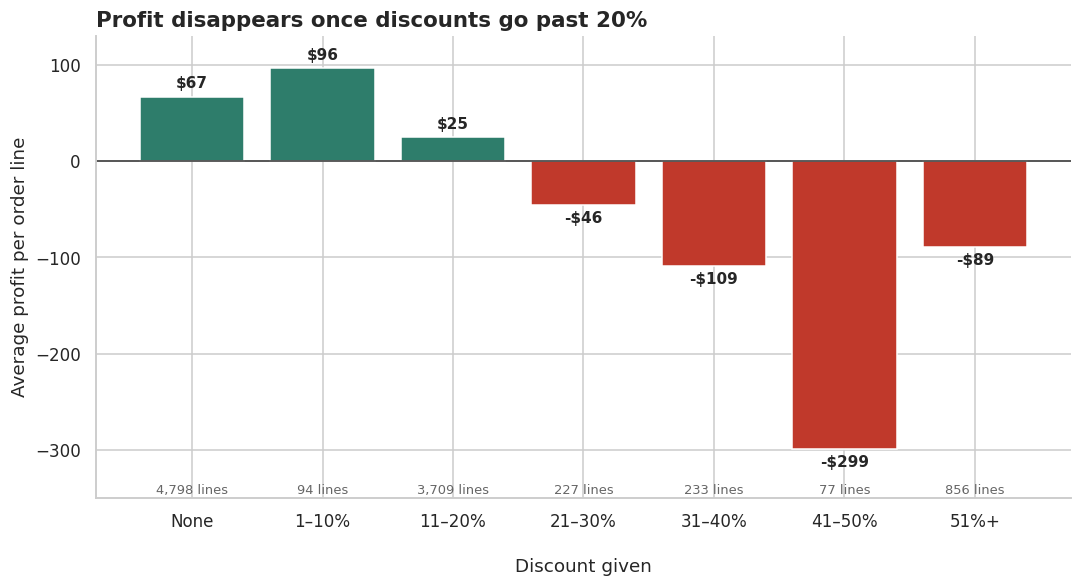

In [11]:
bins   = [-0.01, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0]
labels = ["None", "1–10%", "11–20%", "21–30%", "31–40%", "41–50%", "51%+"]
df["Discount band"] = pd.cut(df["Discount"], bins=bins, labels=labels)

band = df.groupby("Discount band", observed=True)["Profit"].agg(["mean", "count", "sum"])

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = ["#c0392b" if v < 0 else "#2e7d6b" for v in band["mean"]]
ax.bar(band.index.astype(str), band["mean"], color=colors)
ax.axhline(0, color="#333333", lw=1)
for i, (m, n) in enumerate(zip(band["mean"], band["count"])):
    ax.text(i, m + (6 if m >= 0 else -6), f"{'-' if m < 0 else ''}${abs(m):,.0f}", ha="center",
            va="bottom" if m >= 0 else "top", fontsize=10, fontweight="bold")
    ax.text(i, -345, f"{n:,} lines", ha="center", fontsize=8.5, color="#666666")
ax.set_ylim(-350, 130)
ax.set_xlabel("Discount given", labelpad=18)
ax.set_ylabel("Average profit per order line")
ax.set_title("Profit disappears once discounts go past 20%",
             loc="left", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [12]:
heavy = df[df["Discount"] > 0.2]
light = df[df["Discount"] <= 0.2]
print(f"Lines discounted more than 20%: {len(heavy):,}  ({len(heavy)/len(df):.0%} of all lines)")
print(f"Their total profit            : -${abs(heavy['Profit'].sum()):,.0f}")
print(f"Their margin                  : {heavy['Profit'].sum() / heavy['Sales'].sum():.0%}")
print(f"Profit from everything else   : ${light['Profit'].sum():,.0f}")

Lines discounted more than 20%: 1,393  (14% of all lines)
Their total profit            : -$135,376
Their margin                  : -37%
Profit from everything else   : $421,773


If I could only show one chart, it would be this one. Up to a 20% discount, orders still earn money: around $67 per line with no discount and about $25 at 11–20%. Past 20% the average goes negative, and it keeps getting worse. At 41–50% off, each line loses close to $300 on average.

Only about 14% of order lines were discounted that far, but together they lost roughly $135K, a margin of -37%. Everything else added up to about $422K. If those heavy-discount lines had simply broken even, total profit would have been about 47% higher.

One example sticks out. A 3D printer sold at 70% off lost $6,600 on a single order, the worst line in the whole file.

## Where are the losses coming from?

In [13]:
state = df.groupby("State")[["Sales", "Profit"]].sum()
state["Avg discount %"] = df.groupby("State")["Discount"].mean() * 100
state.sort_values("Profit").head(6)

,Sales,Profit,Avg discount %
State,,,
Texas,"170,188.05","-25,729.36",37.02
Ohio,"78,258.14","-16,971.38",32.49
Pennsylvania,"116,511.91","-15,559.96",32.86
Illinois,"80,166.10","-12,607.89",39.00
North Carolina,"55,603.16","-7,490.91",28.35
Colorado,"32,108.12","-6,527.86",31.65


In [14]:
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin %"] = region["Profit"] / region["Sales"] * 100
region["Lines discounted >20%"] = df.groupby("Region")["Discount"].apply(lambda s: (s > 0.2).mean() * 100)
region

,Sales,Profit,Margin %,Lines discounted >20%
Region,,,,
Central,"501,239.89","39,706.36",7.92,27.68
East,"678,781.24","91,522.78",13.48,16.19
South,"391,721.91","46,749.43",11.93,10.56
West,"725,457.82","108,418.45",14.94,3.68


Texas loses about $25.7K even though it sells $170K, and Ohio, Pennsylvania and Illinois each lose between $12K and $17K. Across those four states the average discount is about 36%, compared with 16% for the business as a whole. I didn't expect the pattern to be that clean.

The regions tell the same story. In Central, 28% of order lines are discounted past 20%. In the West it's under 4%. Central's margin is 7.9% and the West's is 14.9%. The West isn't selling anything magical, it just isn't giving the margin away.

## So what should we do?

Here's how I'd sum it up. The business is growing, but it isn't getting more profitable, and the main reason is discounting. About 14% of order lines went out at more than 20% off, and together they lost around $135K. Furniture, and Tables in particular, adds to the problem, and the losses cluster in the Central region and a few states (Texas, Ohio, Pennsylvania, Illinois) where discounts run deepest. The good news is that demand looks healthy: sales are up about 51% since 2014, and the seasonal pattern is steady and predictable.

If I were advising the owner, I'd start with discounts, because it's the cheapest fix with the biggest payoff. A default cap of 20%, with a manager's sign-off for anything higher, goes straight at the largest loss. Next I'd look at why discounts are so much deeper in Central. It could be policy, a few reps, or particular customers, and it's worth finding out which.

Tables deserve a look of their own. They make money when they aren't discounted heavily and lose money when they are, so I'd fix the pricing before thinking about dropping them. In the meantime, lean on what already works: Copiers, Accessories and Paper earn strong margins and fit well into the November–December rush. February is so slow that it's the right month for a targeted offer, not a blanket sale. And it's worth looking after the top 160 or so customers, who bring in nearly half the sales, without paying for their loyalty in deep discounts.

A few honest limits. This is exploratory work, so it shows where to look more than it proves why things happened. We don't have product costs or pricing history, so a loss on a line could come from the discount, from the product's cost, or both. The discount link is strong in the data, but the cleanest way to confirm it would be a small test, such as capping discounts in one region for a quarter and seeing what happens.